# Random Forest with hyperparameter tuning with proper explanations

## Holiday Package Prediciton

### 1) Problem statement.
"Trips & Travel.Com" company wants to enable and establish a viable business model to expand the customer base.


One of the ways to expand the customer base -> introduce a new offering of packages. 
Currently, there are 5 types of packages the company is offering 
    Basic, 
    Standard, 
    Deluxe, 
    Super Deluxe, 
    King. 


Looking at the data of the last year:
    we observed that 18% of the customers purchased the packages. 
    However, the marketing cost was quite high because customers were contacted at random without looking at the available information.
    
The company is now planning to launch a new product i.e. Wellness Tourism Package. 

Wellness Tourism is defined as Travel that allows the traveler to maintain, enhance or kick-start a healthy lifestyle, and support or increase one's sense of well-being.

However, this time company wants to harness the available data of existing and potential customers to make the marketing expenditure more efficient.

### 2) Data Collection.
The Dataset is collected from https://www.kaggle.com/datasets/susant4learning/holiday-package-purchase-prediction
The data consists of 20 column and 4888 rows.

In [1]:
# the overall issue is :

# the stats is convey only 18% of the customers were purchased the packages by last year. this problem is basically happens due to wrong marketing strategy. 
# and the cause is marketing cost were high, the main reason is wrong strategy held like contacting customers by randomly instead of chosing the customer behavior or performance in a database, 
# so the company can't make a real customers or real package buyers. 
# and now, the company is plan to introduce a new package is based on the "wellness"
# so this package is completely based in the health and fitness and some other well-being activities.
# existing there is 5 packages such as Basic, Standard, Deluxe, Super Deluxe, King.


# so the statement is the trips and travel company want to create a viable business model to expand the real customers/buyers base though the new package campaign
# for this new campaign the company want to use exiting information to make the potential customers and also side by side they focus on marketing expenditure more efficient for this new campaign

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")


###########

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, f1_score



%matplotlib inline

In [8]:
df = pd.read_csv("../Sources/Travel.csv")

In [9]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


# EDA 

In [4]:
# checking null values :
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [5]:
# now checking with percentages
null_pct = (df.isnull().mean() * 100).round(2)
print(null_pct[null_pct > 0])

null_pct.describe()

Age                         4.62
TypeofContact               0.51
DurationOfPitch             5.14
NumberOfFollowups           0.92
PreferredPropertyStar       0.53
NumberOfTrips               2.86
NumberOfChildrenVisiting    1.35
MonthlyIncome               4.77
dtype: float64


count    20.000000
mean      1.035000
std       1.784169
min       0.000000
25%       0.000000
50%       0.000000
75%       1.027500
max       5.140000
dtype: float64

In [6]:
# checking gender category
df['Gender'].value_counts() # in this "text error" appears, want to correct the female name

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [7]:
# checking MaritalStatus category
df['MaritalStatus'].value_counts() # in this "logic error", both of them are same single and unmarried, so i change to one category in unmarried 

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64

In [8]:
# checking TypeofContact category
df['TypeofContact'].value_counts()

TypeofContact
Self Enquiry       3444
Company Invited    1419
Name: count, dtype: int64

In [9]:
# checking Occupation category
df['Occupation'].value_counts()

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64

In [10]:
# checking productpitched category
df['ProductPitched'].value_counts()

ProductPitched
Basic           1842
Deluxe          1732
Standard         742
Super Deluxe     342
King             230
Name: count, dtype: int64

In [11]:
# checking designation category
df['Designation'].value_counts()

Designation
Executive         1842
Manager           1732
Senior Manager     742
AVP                342
VP                 230
Name: count, dtype: int64

In [12]:
# checking the no.of trips of customers
df['NumberOfTrips'].value_counts()

NumberOfTrips
2.0     1464
3.0     1079
1.0      620
4.0      478
5.0      458
6.0      322
7.0      218
8.0      105
19.0       1
21.0       1
20.0       1
22.0       1
Name: count, dtype: int64

In [128]:
# these columns are almost same like have same information

# NumberOfChildrenVisiting & NumberOfPersonVisiting
# so i combine these two in single column

# Data Preprocessing :

In [13]:
# backup the original data :

data_v1 = df.copy()

In [14]:
# 1. Gender

In [15]:
data_v1['Gender'] = df['Gender'].str.replace('Fe Male', 'Female')

In [16]:
data_v1['Gender'].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [17]:
# 2. MaritalStatus

In [18]:
data_v1['MaritalStatus'] = df['MaritalStatus'].str.replace('Single', 'Unmarried')

In [19]:
data_v1['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [20]:
# List of numerical column names
num_cols = df.select_dtypes(include='number').columns.tolist()
num_cols

['CustomerID',
 'ProdTaken',
 'Age',
 'CityTier',
 'DurationOfPitch',
 'NumberOfPersonVisiting',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'Passport',
 'PitchSatisfactionScore',
 'OwnCar',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [21]:
# checking with percent and filterout
num = df.select_dtypes(include='number').isnull().mean() * 100
print(num[num > 0])

Age                         4.623568
DurationOfPitch             5.135025
NumberOfFollowups           0.920622
PreferredPropertyStar       0.531915
NumberOfTrips               2.864157
NumberOfChildrenVisiting    1.350245
MonthlyIncome               4.766776
dtype: float64


In [22]:
# List of categorical (string/object) column names
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols

['TypeofContact',
 'Occupation',
 'Gender',
 'ProductPitched',
 'MaritalStatus',
 'Designation']

In [23]:
# checking with percent and filterout
num1 = df.select_dtypes(include='object').isnull().mean() * 100
print(num1[num1 > 0])

TypeofContact    0.511457
dtype: float64


In [125]:
# median imputation for numericals cols:
# mode imputation for categorical cols:

median_impute_cols = [
    'Age',
    'DurationOfPitch',
    'NumberOfFollowups',
    'PreferredPropertyStar',
    'NumberOfTrips',
    'NumberOfChildrenVisiting',
    'MonthlyIncome'
]

mode_impute_cols = [
    'TypeofContact'
]


fill_values = {}

for col in median_impute_cols:
    if col in data_v1.columns:
        fill_values[col] = data_v1[col].median()

for col in mode_impute_cols:
    if col in data_v1.columns:
        fill_values[col] = data_v1[col].mode()[0]

data_v1.fillna(value=fill_values, inplace = True)

In [25]:
data_v1.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [26]:
data_v1.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [27]:
# combining the NumberOfPersonVisiting and NumberOfChildrenVisiting

data_v1["TotalVisiting"] = data_v1['NumberOfPersonVisiting'] + data_v1["NumberOfChildrenVisiting"]

data_v1.drop(
    columns = ['NumberOfPersonVisiting', 'NumberOfChildrenVisiting'], inplace = True
)

In [28]:
data_v1.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'Designation', 'MonthlyIncome', 'TotalVisiting'],
      dtype='object')

# Model Training with sample model algorithms to get understanding the flow

In [40]:
X = data_v1.drop('ProdTaken', axis = 1)
y = data_v1[['ProdTaken']]

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42
)

In [42]:
X_train.shape, X_test.shape

((3910, 18), (978, 18))

In [43]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              4888 non-null   int64  
 1   Age                     4888 non-null   float64
 2   TypeofContact           4888 non-null   object 
 3   CityTier                4888 non-null   int64  
 4   DurationOfPitch         4888 non-null   float64
 5   Occupation              4888 non-null   object 
 6   Gender                  4888 non-null   object 
 7   NumberOfFollowups       4888 non-null   float64
 8   ProductPitched          4888 non-null   object 
 9   PreferredPropertyStar   4888 non-null   float64
 10  MaritalStatus           4888 non-null   object 
 11  NumberOfTrips           4888 non-null   float64
 12  Passport                4888 non-null   int64  
 13  PitchSatisfactionScore  4888 non-null   int64  
 14  OwnCar                  4888 non-null   

In [44]:
# Changing the Categorical features into numerical for model understanding

# 'TypeofContact'
#  'Occupation'
#  'Gender'
#  'ProductPitched'
#  'MaritalStatus'
#  'Designation'

# scaling the numerical columns for equal mean and variance for all numerical features like (-2 to +2 range)

# these two transforms were done after spliting the training dataset cause of data leakage. 

In [45]:
cat_features = X.select_dtypes(include = 'object').columns
num_features = X.select_dtypes(exclude = 'object').columns

# drop='first'         -->  this is to avoid the mirror issues.
# sparse_output=False  -->  encoder compress the format the output , 
# so the pandas can't read and retrive it 
# so the this helps the return it in a default in grid format ,
# so the pandas can easily understand it and able to retrieve it.

cat_transformer = OneHotEncoder(drop='first', sparse_output=False)
numeric_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", cat_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features)
    ],
    remainder='passthrough'
)

preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OneHotEncoder', ...), ('StandardScaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer

In [46]:
data_v1.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'Designation', 'MonthlyIncome', 'TotalVisiting'],
      dtype='object')

In [47]:
X_train = preprocessor.fit_transform(X_train) # this is for model learning 
# to see the parameter like mean and standard deviation for all columns(features) and model will learn this completely.


X_test = preprocessor.transform(X_test)# this is testing data with same training data's parameter to avoid the data leakages, and importantly model prediction would be broken if we use the diff preprocessing settings,
# want to use the same settings for both training and testing to maintain the consistent.
# in this by using the transform alone it will take the parameters from the training data.
# the reason behind the transform for testing data : the model have learn from that settings , suddendly we take the testing data into fit like mean and S.D means and pass it with this means 
# the model will get confused and doesn't make sense of model predictions
# so the rule is , in which settings the model is learned on that exact settings only the new data want to come inside to get the model's best predictions 

In [48]:
pd.DataFrame(X_train)

,OneHotEncoder__TypeofContact_Self Enquiry,OneHotEncoder__Occupation_Large Business,OneHotEncoder__Occupation_Salaried,OneHotEncoder__Occupation_Small Business,OneHotEncoder__Gender_Male,OneHotEncoder__ProductPitched_Deluxe,OneHotEncoder__ProductPitched_King,OneHotEncoder__ProductPitched_Standard,OneHotEncoder__ProductPitched_Super Deluxe,OneHotEncoder__MaritalStatus_Married,...,StandardScaler__CityTier,StandardScaler__DurationOfPitch,StandardScaler__NumberOfFollowups,StandardScaler__PreferredPropertyStar,StandardScaler__NumberOfTrips,StandardScaler__Passport,StandardScaler__PitchSatisfactionScore,StandardScaler__OwnCar,StandardScaler__MonthlyIncome,StandardScaler__TotalVisiting
3995,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-1.020350,1.284279,-0.725271,-0.127737,-0.632399,0.679690,0.782966,-0.382245,-0.774151
2610,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,-0.721400,0.690023,0.282777,-0.725271,1.511598,-0.632399,0.679690,0.782966,-0.459799,0.643615
3083,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-1.020350,0.282777,1.771041,0.418708,-0.632399,0.679690,0.782966,-0.245196,-0.065268
3973,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,-0.721400,-1.020350,1.284279,-0.725271,-0.127737,-0.632399,1.408395,-1.277194,0.213475,-0.065268
4044,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,2.400396,-1.720227,-0.725271,1.511598,-0.632399,-0.049015,-1.277194,-0.024889,2.061382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-0.653841,1.284279,-0.725271,-0.674182,-0.632399,-1.506426,0.782966,-0.536973,0.643615
466,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.455047,-0.898180,-0.718725,1.771041,-1.220627,-0.632399,1.408395,0.782966,1.529609,-0.065268
3092,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.455047,1.545210,0.282777,-0.725271,2.058043,-0.632399,-0.777720,0.782966,-0.360576,0.643615
3772,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.455047,1.789549,1.284279,-0.725271,-0.127737,-0.632399,-1.506426,0.782966,-0.252799,0.643615


In [49]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3910 entries, 3995 to 860
Data columns (total 27 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   OneHotEncoder__TypeofContact_Self Enquiry   3910 non-null   float64
 1   OneHotEncoder__Occupation_Large Business    3910 non-null   float64
 2   OneHotEncoder__Occupation_Salaried          3910 non-null   float64
 3   OneHotEncoder__Occupation_Small Business    3910 non-null   float64
 4   OneHotEncoder__Gender_Male                  3910 non-null   float64
 5   OneHotEncoder__ProductPitched_Deluxe        3910 non-null   float64
 6   OneHotEncoder__ProductPitched_King          3910 non-null   float64
 7   OneHotEncoder__ProductPitched_Standard      3910 non-null   float64
 8   OneHotEncoder__ProductPitched_Super Deluxe  3910 non-null   float64
 9   OneHotEncoder__MaritalStatus_Married        3910 non-null   float64
 10  OneHotEncoder__

In [50]:
models = {
    "Logistic Regression" : LogisticRegression(),
    "Decision Tree" : DecisionTreeClassifier(),
    "Random Forest" : RandomForestClassifier()
}

In [51]:
models

{'Logistic Regression': LogisticRegression(),
 'Decision Tree': DecisionTreeClassifier(),
 'Random Forest': RandomForestClassifier()}

In [52]:
for mdl in models:
    model = models[mdl]

    ## training :
    model.fit(
        X_train,y_train 
    )
    ## prediction :
    y_train_pred = model.predict(X_train) # checking how model learned (old data)
    y_test_pred = model.predict(X_test) # checking how model predict (new data)

    ## metrics :

    # accuracy
    model_train_accuracy = accuracy_score(y_train, y_train_pred)
    model_test_accuracy = accuracy_score(y_test, y_test_pred)
    # precision score
    model_train_precision = precision_score(y_train, y_train_pred)
    model_test_precision = precision_score(y_test, y_test_pred)
    # recall
    model_train_recall = recall_score(y_train, y_train_pred)
    model_test_recall = recall_score(y_test, y_test_pred)


    print(f"//{mdl}//")

    print("Model performance")
    print(f"Accuracy:  Training {model_train_accuracy} VS Testing {model_test_accuracy}")
    print(f"precision: Training {model_test_precision} VS Testing {model_test_precision}")
    print(f"recall:    Training {model_test_recall}    VS Testing {model_test_recall} \n")

//Logistic Regression//
Model performance
Accuracy:  Training 0.8468030690537084 VS Testing 0.8353783231083844
precision: Training 0.6785714285714286 VS Testing 0.6785714285714286
recall:    Training 0.29842931937172773    VS Testing 0.29842931937172773 

//Decision Tree//
Model performance
Accuracy:  Training 1.0 VS Testing 0.9008179959100204
precision: Training 0.7701149425287356 VS Testing 0.7701149425287356
recall:    Training 0.7015706806282722    VS Testing 0.7015706806282722 

//Random Forest//
Model performance
Accuracy:  Training 1.0 VS Testing 0.9192229038854806
precision: Training 0.9516129032258065 VS Testing 0.9516129032258065
recall:    Training 0.6178010471204188    VS Testing 0.6178010471204188 



# Random Forest with Hyperparameter tuning to find best params

In [ ]:
# Max Depth

# how deep each decision tree grows

# small depth :
# -> Fast
# -> very simple
# -> Less overfit
# -> may be get underfit due to less tree/simple learning 

# large depth:
# -> Learn complex patterns
# -> better training accuracy
# -> higher overfitting risk


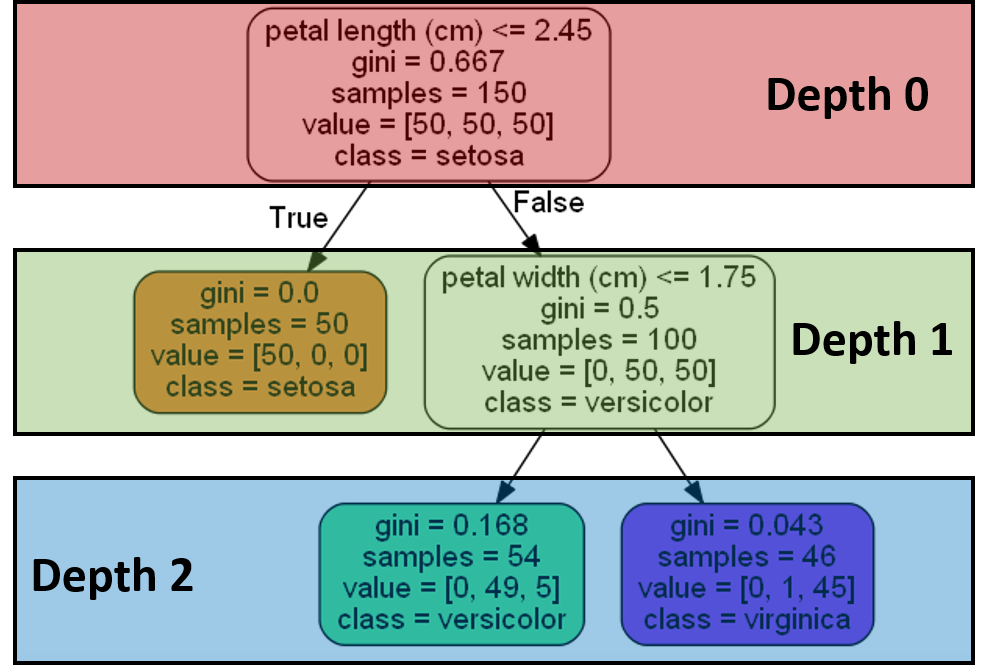

In [9]:
from IPython.display import Image, display
img = "../../My notes/max_depth - Tree Algorithms.png"
display(Image(filename = img, width = 400))

In [ ]:
# Max Features/columns

# max_features = 3 -> it will limit each node only have the 3 columns/features

# randomness -> imporve performance -> overll all model get undertsand the patterns and with any bias

# max_feature = smaller:
# -> more randomness which gives the less overfit and trees become diverse
# -> so each model have unique random features and learned patterns

# max_feature = larger:
# -> less randomness which give the high correlation bt the models and all model looks same compare to each other, which means if all model looks same means , then why random forest exists ,become pointless

# -> more correlation bt trees and that not the main idea of the random forest.

# -> stronger individual trees which give more correlation bt trees

# conclude :
# -> always define the max_features to less to get more randomness

In [ ]:
# min_samples_split

# it avoid the attempt of overfitting 
# it setup the node spliting by a value

# this prevents from creating tiny branches - reduce noise

# small values :

# -> aggresive tree growth

# -> more detailed learning

# -> overfitting risk 

# large values :

# -> more controlled growth

# -> simpler models

# -> better generalizations 

# -> may reduce overfitting 

# -> may attempt to underfitting

# conclude : -> this sample split always determine the value from the total size of the data. choose balance and correctly

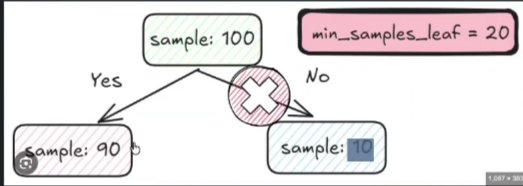

In [12]:
from IPython.display import Image, display
img = "../../My notes/min_sample_split - Tree Algorithms.png"
display(Image(filename = img, width = 400))

In [ ]:
# n_estimators 

# how many decision tree should exist in random forest

# in final predictions :

# -> decide with majority voting classifier with all D.T

# pros :

# -> impove more accuravy

# -> reduce variance / reduce overfitting 

# -> increase stability in both train and test

# cons :

# -> more computation power

# -> more memory

# -> slower training 

# estimator = more

# -> consume more time

# -> more computational power

# estimator = less

# -> fast

# -> less accuracy

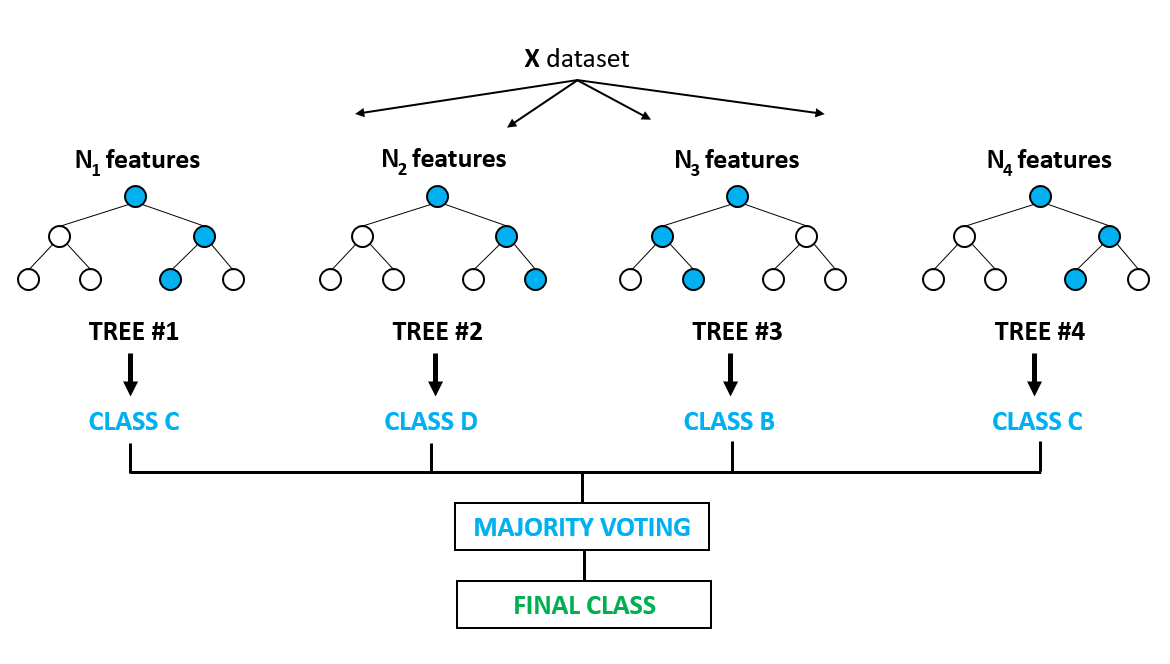

In [11]:
from IPython.display import Image, display
img = "../../My notes/n_estimators - Tree Algorithms.png"
display(Image(filename = img, width = 500))

In [84]:
# starts here :

In [88]:
# all parameters have a thumb rule , checkout via docs

rf_params = {
    "max_depth" : [5,8,15,None,10],
    "max_features" : [5,7,"auto", 8],
    "min_samples_split" : [2,8,20,15],
    "n_estimators" : [100,200,500,1000]
}

In [90]:
randomcv_model = [
    ("RF",RandomForestClassifier(),rf_params)
]

In [91]:
randomcv_model

[('RF',
  RandomForestClassifier(),
  {'max_depth': [5, 8, 15, None, 10],
   'max_features': [5, 7, 'auto', 8],
   'min_samples_split': [2, 8, 20, 15],
   'n_estimators': [100, 200, 500, 1000]})]

In [126]:
from sklearn.model_selection import RandomizedSearchCV # this is one of the hyperparameter tuning technique

In [127]:
model_param = {}

for name, model, params in randomcv_model:
    random = RandomizedSearchCV(
        estimator = model,
        param_distributions = params,
        n_iter = 100,
        cv = 3,
        verbose = 2,
        n_jobs = -1
    )
    random.fit(X_train, y_train)
    model_param[name] = random.best_params_

Fitting 3 folds for each of 100 candidates, totalling 300 fits


In [128]:
for model_name in model_param:
    print(model_name)
    print(model_param[model_name])

RF
{'n_estimators': 1000, 'min_samples_split': 2, 'max_features': 7, 'max_depth': None}


# here i find the best parameters for this problem , and now take that parameters and
# then again want to train the model with that best params...

In [119]:
RF_model =  RandomForestClassifier(
        n_estimators = 500,
        min_samples_split = 2,
        max_features = 8,
        max_depth = None
    )


In [120]:
RF_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",8
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_tr

In [124]:
y_train_pred = RF_model.predict(X_train)
y_test_pred  = RF_model.predict(X_test)


## metrics :
# accuracy
model_train_accuracy = accuracy_score(y_train, y_train_pred)
model_test_accuracy = accuracy_score(y_test, y_test_pred)
# precision score
model_train_precision = precision_score(y_train, y_train_pred)
model_test_precision = precision_score(y_test, y_test_pred)
# recall
model_train_recall = recall_score(y_train, y_train_pred)
model_test_recall = recall_score(y_test, y_test_pred)
    
    
print(f"//{mdl}// \n")
print("Model performance")
print(f"Accuracy:  Training {model_train_accuracy} VS Testing {model_test_accuracy}")
print(f"precision: Training {model_test_precision} VS Testing {model_test_precision}")
print(f"recall:    Training {model_test_recall}    VS Testing {model_test_recall}")

//Random Forest// 

Model performance
Accuracy:  Training 1.0 VS Testing 0.9253578732106339
precision: Training 0.9538461538461539 VS Testing 0.9538461538461539
recall:    Training 0.6492146596858639    VS Testing 0.6492146596858639
